# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 4: Creation and Display of Fuzzy Relations**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create and display a simple fuzzy relation between two fuzzy sets using Python.

### 2. Theory: Fuzzy Relations and Cartesian Products

A classical binary relation $R$ between two crisp sets $X$ and $Y$ is a subset of the Cartesian product $X \times Y$. An ordered pair $(x, y)$ either belongs to the relation or does not:
$$\chi_R(x, y) \in \{0, 1\}$$

A **Fuzzy Relation** $R$ between two fuzzy sets $A \subseteq X$ and $B \subseteq Y$ generalizes this concept by assigning a degree of association or relationship strength between elements $x$ and $y$:
$$\mu_R(x, y) \in [0, 1]$$

#### 1. Fuzzy Cartesian Product via Min T-Norm:
Given fuzzy set $A$ on universe $X$ and fuzzy set $B$ on universe $Y$, the fuzzy Cartesian product $R = A \times B$ is defined by:
$$\mu_R(x, y) = \min\big(\mu_A(x), \mu_B(y)\big)$$

#### 2. Max-Min Composition:
If $R$ is a fuzzy relation on $X \times Y$ and $S$ is a fuzzy relation on $Y \times Z$, their **Max-Min composition** $T = R \circ S$ on $X \times Z$ is defined by:
$$\mu_T(x_i, z_k) = \max_{y_j \in Y} \min\big(\mu_R(x_i, y_j), \mu_S(y_j, z_k)\big)$$
This operation acts as the fuzzy counterpart to matrix multiplication, forming the foundational computational engine of fuzzy inference engines.

### 3. Step 1: Constructing Fuzzy Sets and the Cartesian Product Relation

#### What this cell does:
We define two discrete fuzzy sets:
- Set $A$ over universe $X = \{x_1, x_2, x_3, x_4, x_5\}$:
  $$A = [0.2, 0.5, 0.8, 1.0, 0.4]$$
- Set $B$ over universe $Y = \{y_1, y_2, y_3, y_4\}$:
  $$B = [0.3, 0.7, 0.9, 0.5]$$
We compute the relation matrix $R = A \times B$ using the min-operator outer product.

In [1]:
import numpy as np

# Discrete universes
X_labels = ['x1', 'x2', 'x3', 'x4', 'x5']
Y_labels = ['y1', 'y2', 'y3', 'y4']

# Membership grade vectors
mu_A = np.array([0.2, 0.5, 0.8, 1.0, 0.4])
mu_B = np.array([0.3, 0.7, 0.9, 0.5])

# Compute Cartesian Product Relation R = A x B via min operator
# R[i, j] = min(mu_A[i], mu_B[j])
R = np.minimum.outer(mu_A, mu_B)

print("Fuzzy Sets defined:")
print("mu_A =", mu_A)
print("mu_B =", mu_B)
print(f"\nFuzzy Relation Matrix R (shape {R.shape}):")
print(R)


Fuzzy Sets defined:
mu_A = [0.2 0.5 0.8 1.  0.4]
mu_B = [0.3 0.7 0.9 0.5]

Fuzzy Relation Matrix R (shape (5, 4)):
[[0.2 0.2 0.2 0.2]
 [0.3 0.5 0.5 0.5]
 [0.3 0.7 0.8 0.5]
 [0.3 0.7 0.9 0.5]
 [0.3 0.4 0.4 0.4]]


### 4. Step 2: Max-Min Composition of Fuzzy Relations

#### What this cell does:
We define a secondary fuzzy relation $S$ on $Y \times Z$ where $Z = \{z_1, z_2, z_3\}$ and execute the Max-Min composition:
$$T = R \circ S$$

In [2]:
# Define relation S between Y and Z (4 x 3)
Z_labels = ['z1', 'z2', 'z3']
S = np.array([
    [0.6, 0.8, 0.2],
    [0.7, 0.4, 0.9],
    [0.5, 0.3, 0.8],
    [0.9, 0.5, 0.4]
])

def max_min_composition(rel_R, rel_S):
    '''Computes Max-Min composition T = R o S'''
    n_rows = rel_R.shape[0]
    n_cols = rel_S.shape[1]
    T = np.zeros((n_rows, n_cols))
    
    for i in range(n_rows):
        for k in range(n_cols):
            # Element-wise min over connecting dimension, then max
            T[i, k] = np.max(np.minimum(rel_R[i, :], rel_S[:, k]))
    return T

T = max_min_composition(R, S)

print("=" * 60)
print("       MAX-MIN COMPOSITION RESULT MATRIX T = R o S")
print("=" * 60)
print(f"{'':<6} | {'z1':<12} | {'z2':<12} | {'z3':<12}")
print("-" * 60)
for idx, label in enumerate(X_labels):
    print(f"{label:<6} | {T[idx, 0]:<12.2f} | {T[idx, 1]:<12.2f} | {T[idx, 2]:<12.2f}")
print("=" * 60)


       MAX-MIN COMPOSITION RESULT MATRIX T = R o S
       | z1           | z2           | z3          
------------------------------------------------------------
x1     | 0.20         | 0.20         | 0.20        
x2     | 0.50         | 0.50         | 0.50        
x3     | 0.70         | 0.50         | 0.80        
x4     | 0.70         | 0.50         | 0.80        
x5     | 0.40         | 0.40         | 0.40        


### 5. Step 3: Heatmap Visualization of Fuzzy Relations

#### What this cell does:
We display the fuzzy relations $R$, $S$, and their composition $T$ as annotated heatmaps with colorbars and numerical cell values.

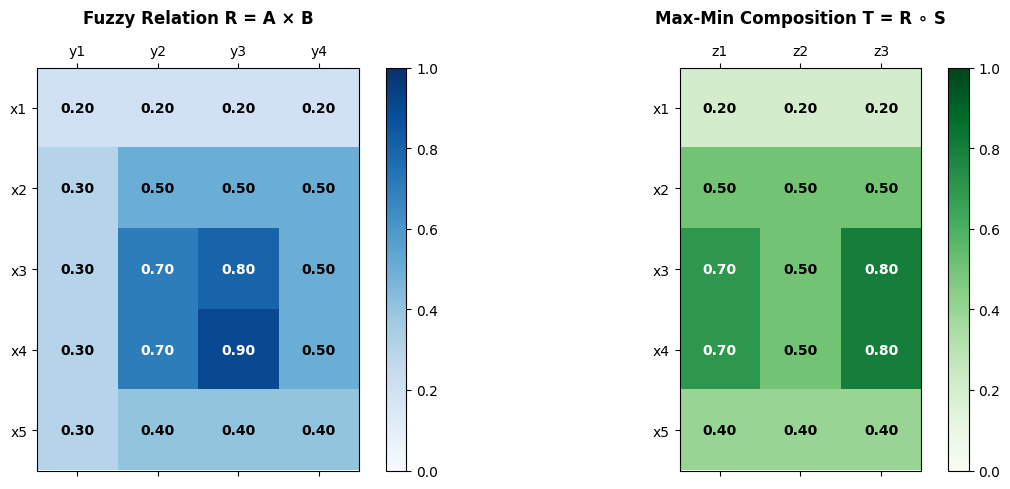

In [3]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Relation R
cax1 = ax1.matshow(R, cmap='Blues', vmin=0, vmax=1)
fig.colorbar(cax1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('Fuzzy Relation R = A × B', fontsize=12, fontweight='bold', pad=15)
ax1.set_xticks(range(len(Y_labels)))
ax1.set_yticks(range(len(X_labels)))
ax1.set_xticklabels(Y_labels)
ax1.set_yticklabels(X_labels)

# Annotate numerical values
for i in range(len(X_labels)):
    for j in range(len(Y_labels)):
        ax1.text(j, i, f'{R[i, j]:.2f}', ha='center', va='center',
                 color='white' if R[i, j] > 0.5 else 'black', fontweight='bold')

# Plot Composition T
cax2 = ax2.matshow(T, cmap='Greens', vmin=0, vmax=1)
fig.colorbar(cax2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('Max-Min Composition T = R ∘ S', fontsize=12, fontweight='bold', pad=15)
ax2.set_xticks(range(len(Z_labels)))
ax2.set_yticks(range(len(X_labels)))
ax2.set_xticklabels(Z_labels)
ax2.set_yticklabels(X_labels)

for i in range(len(X_labels)):
    for k in range(len(Z_labels)):
        ax2.text(k, i, f'{T[i, k]:.2f}', ha='center', va='center',
                 color='white' if T[i, k] > 0.5 else 'black', fontweight='bold')

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Input Element Pair | $\mu_A(x_i)$ | $\mu_B(y_j)$ | Relation Strength $R(x_i, y_j) = \min(\mu_A, \mu_B)$ |
| :---: | :---: | :---: | :---: |
| $(x_1, y_1)$ | $0.20$ | $0.30$ | $0.20$ |
| $(x_3, y_2)$ | $0.80$ | $0.70$ | $0.70$ |
| $(x_4, y_3)$ | $1.00$ | $0.90$ | $0.90$ |
| $(x_5, y_4)$ | $0.40$ | $0.50$ | $0.40$ |

#### Key Observations in Simple Words:
1. **Bottleneck Property of Min:** The relation strength between $x_i$ and $y_j$ is upper-bounded by the weaker of the two memberships (the bottleneck principle).
2. **Matrix Interpretation:** Fuzzy relations represent continuous connections between spaces. For instance, in medical diagnosis, $X$ can represent patient symptoms, $Y$ disease probabilities, and $Z$ recommended medications.
3. **Max-Min Chaining:** Composition allows indirect inference: knowing how symptoms map to diseases ($R$) and how diseases map to treatments ($S$), Max-Min composition directly infers how symptoms map to treatments ($T$).

---
### 7. Conclusion
1. We created a fuzzy Cartesian relation between two fuzzy sets in Python using the minimum operator.
2. We implemented and executed the Max-Min fuzzy composition algorithm.
3. We visually inspected relational dependencies through color-coded heatmaps with direct cell value annotations.